<a href="https://colab.research.google.com/github/erikarosado/ia-y-aprendizaje-automatico/blob/main/Serie_de_tiempo_ErikaRosado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Inteligencia Artificial y Aprendizaje Automático
## Maestría en Inteligencia Artificial Aplicada
Dr Luis Eduardo Falcón Morales — Tecnológico de Monterrey

### Actividad Individual: Pronósticos con Series de Tiempo

**Nombre:**  Erika Rosado Treviño
**Matrícula:** A00846135

Modelos: 1. Ingenuo · 2. ARIMA · 3. Prophet · 4. LSTM

## A - Introducción

In [3]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping
import itertools

np.random.seed(42); tf.random.set_seed(42)

## Ejercicio 1
**1a.** Descarga de Google Trends el CSV con: término "chocolate", país Estados Unidos, del 01-mar-2006 al 28-feb-2026, "todas las categorías", "búsqueda web". Guárdalo en la misma carpeta de este notebook (por ejemplo `multiTimeline.csv`) y ajusta la variable `archivo`.

In [4]:
# Ejercicios 1a y 1b.
archivo = "multiTimeline.csv"   # <-- nombre del CSV descargado de Google Trends

# El CSV de Trends trae 1-2 líneas de encabezado antes de la tabla real; la localizamos.
with open(archivo, encoding="utf-8-sig") as f:
    lineas = f.read().splitlines()
cabeceras = ("mes", "month", "semana", "week", "día", "day", "time", "tiempo", "fecha", "date")
ini = next((i for i, l in enumerate(lineas)
            if l.split(",")[0].strip().strip('"').lower() in cabeceras), 0)

dfp = pd.read_csv(archivo, skiprows=ini, encoding="utf-8-sig")
dfp.columns = ["ds", "y"]
dfp["y"] = pd.to_numeric(dfp["y"].astype(str).str.replace("<1", "0.5"), errors="coerce")
dfp["ds"] = pd.to_datetime(dfp["ds"]) + pd.offsets.MonthEnd(0)      # YYYY-MM-DD, fin de mes
dfp = dfp[(dfp["ds"] >= "2006-03-01") & (dfp["ds"] <= "2026-02-28")].reset_index(drop=True)

print("Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.")
print("Formato requerido por el modelo Prophet de Meta:")
print("Dimensión del DataFrame:", dfp.shape)
print(dfp.head())
print(dfp.tail())

Serie de tiempo sobre el interés de búsqueda de Chocolate en EEUU en Google.
Formato requerido por el modelo Prophet de Meta:
Dimensión del DataFrame: (240, 2)
          ds   y
0 2006-03-31  32
1 2006-04-30  33
2 2006-05-31  31
3 2006-06-30  29
4 2006-07-31  30
            ds    y
235 2025-10-31   66
236 2025-11-30   78
237 2025-12-31  100
238 2026-01-31   76
239 2026-02-28   80


In [5]:
# Ejercicio 1c.
dfr = dfp.set_index("ds")[["y"]].copy()
try:
    dfr = dfr.asfreq("ME")      # pandas >= 2.2
except ValueError:
    dfr = dfr.asfreq("M")       # pandas < 2.2

print("Formato requerido por los modelos restantes:")
print(dfr.shape)
print(dfr.head())
print(dfr.index)
print("Valores faltantes:", dfr["y"].isna().sum())

Formato requerido por los modelos restantes:
(240, 1)
             y
ds            
2006-03-31  32
2006-04-30  33
2006-05-31  31
2006-06-30  29
2006-07-31  30
DatetimeIndex(['2006-03-31', '2006-04-30', '2006-05-31', '2006-06-30',
               '2006-07-31', '2006-08-31', '2006-09-30', '2006-10-31',
               '2006-11-30', '2006-12-31',
               ...
               '2025-05-31', '2025-06-30', '2025-07-31', '2025-08-31',
               '2025-09-30', '2025-10-31', '2025-11-30', '2025-12-31',
               '2026-01-31', '2026-02-28'],
              dtype='datetime64[ns]', name='ds', length=240, freq='ME')
Valores faltantes: 0


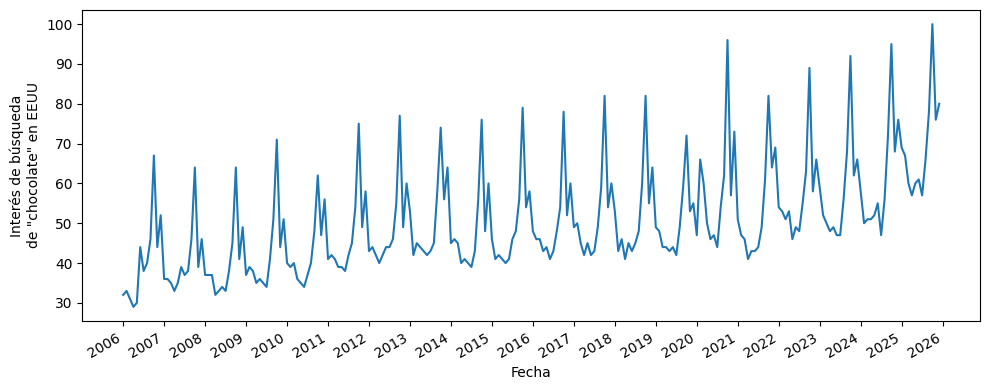

In [6]:
plt.rcParams['figure.figsize'] = (10,4)
fig, ax = plt.subplots()
ax.plot(dfp['y'])
ax.set_xlabel('Fecha')
ax.set_ylabel('Interés de búsqueda\nde "chocolate" en EEUU')
xticks_locs = np.arange(0, len(dfp)+12, 12)
xticks_labels = np.arange(2006, 2027, 1)
plt.xticks(xticks_locs, xticks_labels)
fig.autofmt_xdate()
plt.tight_layout()

In [7]:
# Partición
testP = dfp[-12:]; valP = dfp[-24:-12]; trainP = dfp[:-24]
testR = dfr[-12:]; valR = dfr[-24:-12]; trainR = dfr[:-24]
print(len(trainR), len(valR), len(testR))

def mae(a, b): return mean_absolute_error(np.asarray(a), np.asarray(b))

def plot_pred(pred, titulo, ctx=36):
    """Contexto de entrenamiento + valores reales de validación + predicción."""
    plt.figure(figsize=(10,4))
    plt.plot(trainR.index[-ctx:], trainR["y"][-ctx:], label="Train (contexto)", color="gray")
    plt.plot(valR.index, valR["y"], label="Real (val)", marker="o")
    plt.plot(valR.index, pred, label="Predicción", marker="x", linestyle="--")
    plt.title(titulo); plt.legend(); plt.tight_layout(); plt.show()

216 12 12


## B - Modelo ingenuo
### Ejercicio 2
**Ejercicio 2a:**

**MAE vs. MSE — ventajas y desventajas**

*Ventajas del MAE:* (1) se expresa en las mismas unidades de la serie (aquí, puntos de interés de búsqueda de 0 a 100), por lo que se interpreta directamente como "el error promedio"; (2) es más robusto a valores atípicos, porque penaliza linealmente y no al cuadrado; (3) todas las desviaciones pesan lo mismo.

*Desventajas del MAE:* (1) no penaliza especialmente los errores grandes, que en ciertos problemas son los más costosos; (2) no es diferenciable en cero, lo que lo hace menos cómodo como función de pérdida para optimización basada en gradiente (aunque en la práctica funciona bien); (3) su optimización apunta a la mediana condicional y no a la media.

*MSE:* es diferenciable, tiene solución cerrada en regresión lineal y castiga fuertemente los errores grandes; pero queda en unidades al cuadrado (se suele usar RMSE) y es muy sensible a atípicos.

In [8]:
# Ejercicio 2b: modelo ingenuo = repetir el último valor observado de train.
pred_naive  = np.repeat(trainR["y"].iloc[-1], len(valR))
maeNaive    = mae(valR["y"], pred_naive)

# Variante adicional (baseline más exigente): ingenuo estacional = mismo mes del año anterior.
pred_snaive = trainR["y"].iloc[-12:].values
maeSNaive   = mae(valR["y"], pred_snaive)

print('\nError-modelo-Naive : MAE: %.3f' % maeNaive)
print('Error-modelo-Naive estacional (extra): MAE: %.3f' % maeSNaive)


Error-modelo-Naive : MAE: 12.917
Error-modelo-Naive estacional (extra): MAE: 3.417


**Ejercicio 2c:**

El MAE del modelo ingenuo, `maeNaive = 12.92`, significa que, en promedio, al predecir cada mes del año de validación con el último valor de entrenamiento nos equivocamos 12.92 puntos de la escala 0–100 de Google Trends, es decir, aproximadamente 21.2% del nivel medio de la serie (`valR["y"].mean() = 60.92`). Como la serie del chocolate tiene una estacionalidad marcada (picos en febrero por San Valentín, octubre por Halloween y diciembre por las fiestas), repetir el último valor ignora ese patrón, por lo que este MAE es la **cota que cualquier modelo debe superar**. El ingenuo estacional (`maeSNaive`) es un baseline más justo para esta serie.

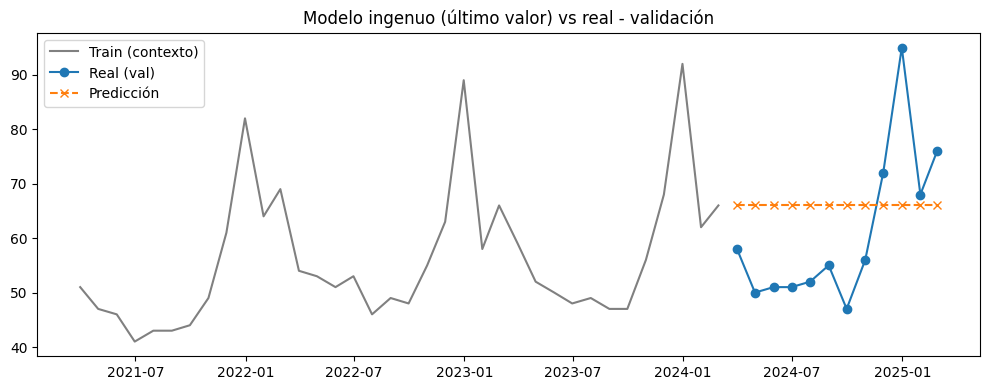

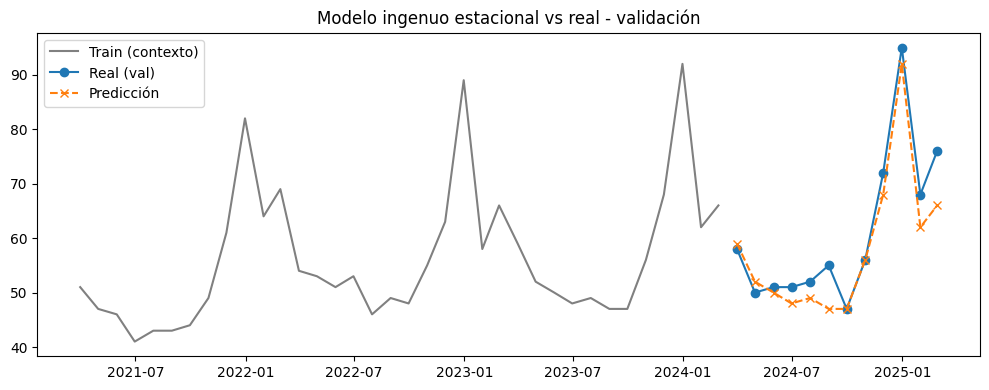

In [9]:
# Ejercicio 2d:
plot_pred(pred_naive,  "Modelo ingenuo (último valor) vs real - validación")
plot_pred(pred_snaive, "Modelo ingenuo estacional vs real - validación")

## C - Modelo ARIMA
### Ejercicio 3

In [10]:
# Ejercicio 3a - ARIMA
def fc_arima(y, h, order, seasonal=(0,0,0,0)):
    m = SARIMAX(y, order=order, seasonal_order=seasonal,
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    return np.asarray(m.forecast(h))

h = len(valR)
# 1) Modelo sencillo de partida
pred0 = fc_arima(trainR["y"], h, (1,1,1))
print("ARIMA(1,1,1) base            MAE: %.3f" % mae(valR["y"], pred0))

# 2) ARIMA no estacional: búsqueda pequeña de (p,d,q)
res = []
for p, d, q in itertools.product(range(0,3), range(0,2), range(0,3)):
    try:
        res.append(((p,d,q), (0,0,0,0), mae(valR["y"], fc_arima(trainR["y"], h, (p,d,q)))))
    except Exception: pass

# 3) Extensión estacional (SARIMA, s=12), pues la serie es mensual y estacional
for (p,d,q), (P,D,Q) in itertools.product([(1,0,0),(1,1,1),(0,1,1),(2,0,0),(1,0,1)],
                                          [(0,1,1),(1,1,1),(1,1,0),(1,0,1)]):
    try:
        res.append(((p,d,q), (P,D,Q,12), mae(valR["y"], fc_arima(trainR["y"], h, (p,d,q), (P,D,Q,12)))))
    except Exception: pass

tabla = pd.DataFrame(res, columns=["order","seasonal_order","MAE_val"]).sort_values("MAE_val")
print(tabla.head(8).to_string(index=False))

best_order, best_seas, maeARIMA = tabla.iloc[0]
best_order, best_seas = tuple(best_order), tuple(best_seas)
pred_arima = fc_arima(trainR["y"], h, best_order, best_seas)
print("\nMejor configuración:", best_order, best_seas)

ARIMA(1,1,1) base            MAE: 12.070
    order seasonal_order  MAE_val
(1, 0, 0)  (1, 0, 1, 12) 3.369445
(2, 0, 0)  (1, 0, 1, 12) 3.379964
(1, 0, 1)  (1, 0, 1, 12) 3.446154
(0, 1, 1)  (1, 0, 1, 12) 3.455801
(0, 1, 1)  (1, 1, 0, 12) 3.480275
(1, 1, 1)  (1, 1, 0, 12) 3.564245
(0, 1, 1)  (0, 1, 1, 12) 3.576161
(1, 1, 1)  (1, 0, 1, 12) 3.579654

Mejor configuración: (1, 0, 0) (1, 0, 1, 12)


In [11]:
print('\nError-modelo-ARIMA : MAE: %.3f' % maeARIMA)


Error-modelo-ARIMA : MAE: 3.369


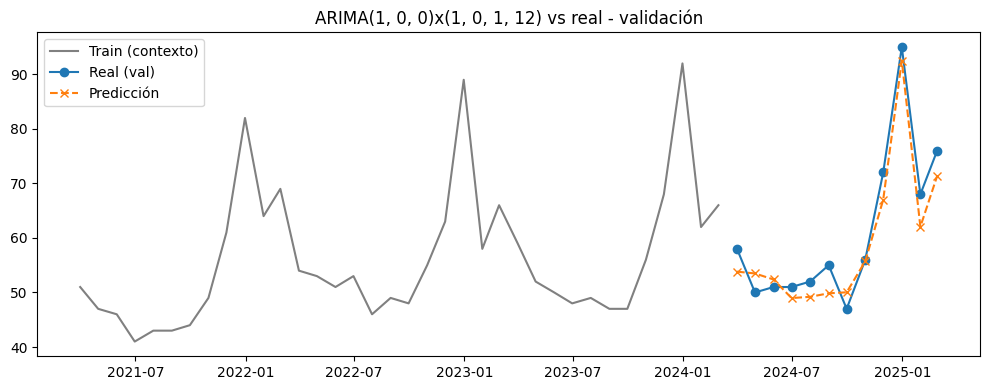

In [12]:
# Ejercicio 3b. ARIMA-gráfica:
plot_pred(pred_arima, f"ARIMA{best_order}x{best_seas} vs real - validación")

## D - Modelo Prophet
### Ejercicio 4

In [13]:
# Ejercicio 4a - Prophet
def fc_prophet(train_df, ds_future, **kw):
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False, **kw)
    m.fit(train_df[["ds","y"]])
    return m.predict(pd.DataFrame({"ds": ds_future}))["yhat"].values

# 1) Modelo sencillo
pred_p0 = fc_prophet(trainP, valP["ds"])
print("Prophet base MAE: %.3f" % mae(valP["y"], pred_p0))

# 2) Búsqueda pequeña de hiperparámetros
resP = []
for mode, cps, sps in itertools.product(["additive","multiplicative"], [0.01,0.05,0.1,0.5], [1,10]):
    p = fc_prophet(trainP, valP["ds"], seasonality_mode=mode,
                   changepoint_prior_scale=cps, seasonality_prior_scale=sps)
    resP.append((mode, cps, sps, mae(valP["y"], p)))
tablaP = pd.DataFrame(resP, columns=["mode","changepoint_prior","seasonality_prior","MAE_val"]).sort_values("MAE_val")
print(tablaP.head(6).to_string(index=False))

bestP = tablaP.iloc[0]
best_prophet_kw = dict(seasonality_mode=bestP["mode"],
                       changepoint_prior_scale=float(bestP["changepoint_prior"]),
                       seasonality_prior_scale=float(bestP["seasonality_prior"]))
pred_prophet = fc_prophet(trainP, valP["ds"], **best_prophet_kw)
maeProphet = mae(valP["y"], pred_prophet)

Prophet base MAE: 4.322
          mode  changepoint_prior  seasonality_prior  MAE_val
multiplicative               0.01                  1 3.521388
multiplicative               0.01                 10 3.527456
multiplicative               0.10                  1 3.557877
multiplicative               0.10                 10 3.597692
multiplicative               0.05                 10 3.658608
multiplicative               0.05                  1 3.738983


In [14]:
print('\nError-modelo-Prophet-Facebook : MAE: %.3f' % maeProphet)


Error-modelo-Prophet-Facebook : MAE: 3.521


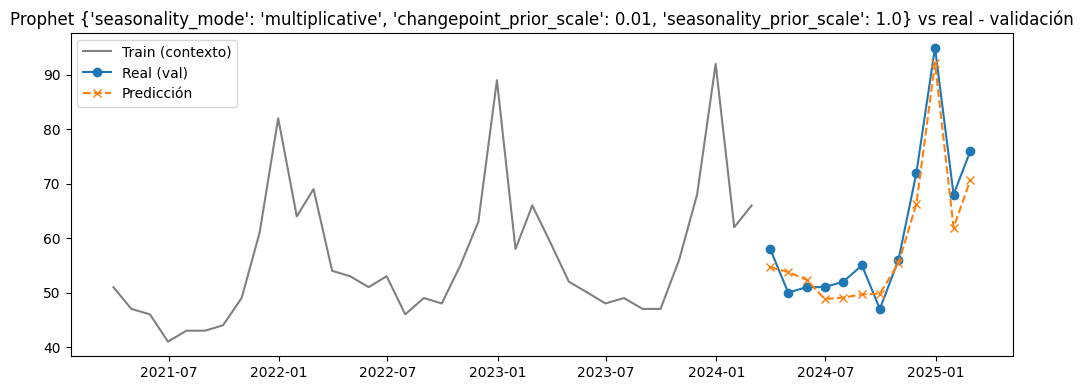

In [15]:
# Ejercicio 4b. Prophet-gráfica:
plot_pred(pred_prophet, f"Prophet {best_prophet_kw} vs real - validación")

## E - Modelo LSTM
### Ejercicio 5
Se escala con `MinMaxScaler` ajustado **solo con train** (para no filtrar información de validación), se generan secuencias de longitud 12 sobre `df_tv = trainR + valR`, y las ventanas cuyo objetivo cae en el último año forman la validación. El MAE final se calcula con un **pronóstico recursivo de 12 meses** (comparable con los demás modelos, que también predicen el año completo sin ver datos reales de validación).

In [16]:
# Ejercicio 5a - LSTM
SEQ = 12
df_tv = pd.concat([trainR, valR])
n_tr  = len(trainR)

scaler = MinMaxScaler().fit(trainR[["y"]])
sc = scaler.transform(df_tv[["y"]]).ravel()

def make_seq(a, L):
    X = np.array([a[i:i+L] for i in range(len(a)-L)])[..., None]
    return X, a[L:]

X, Y = make_seq(sc, SEQ)
split = n_tr - SEQ            # ventanas cuyo objetivo está en el año de validación: desde aquí
Xtr, Ytr, Xv, Yv = X[:split], Y[:split], X[split:], Y[split:]
print(Xtr.shape, Xv.shape)

def build_lstm(units=32):
    m = Sequential([Input((SEQ,1)), LSTM(units), Dense(1)])
    m.compile(optimizer="adam", loss="mae")
    return m

def recursive_forecast(model, hist_scaled, h):
    w, out = list(hist_scaled[-SEQ:]), []
    for _ in range(h):
        p = model.predict(np.array(w[-SEQ:])[None, :, None], verbose=0)[0,0]
        out.append(p); w.append(p)
    return np.array(out)

es = EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
lstm = build_lstm(32)
hist = lstm.fit(Xtr, Ytr, validation_data=(Xv, Yv), epochs=300, batch_size=16,
                callbacks=[es], verbose=0)
epochs_usadas = max(len(hist.history["loss"]) - 20, 20)

pred_lstm = scaler.inverse_transform(recursive_forecast(lstm, sc[:n_tr], len(valR)).reshape(-1,1)).ravel()
maeLSTM = mae(valR["y"], pred_lstm)

pred_1step = scaler.inverse_transform(lstm.predict(Xv, verbose=0)).ravel()
print("LSTM un-paso-adelante (con datos reales de entrada) MAE: %.3f" % mae(valR["y"], pred_1step))

(204, 12, 1) (12, 12, 1)
LSTM un-paso-adelante (con datos reales de entrada) MAE: 4.312


In [17]:
print('\nError-modelo-LSTM : MAE: %.3f' % maeLSTM)


Error-modelo-LSTM : MAE: 4.025


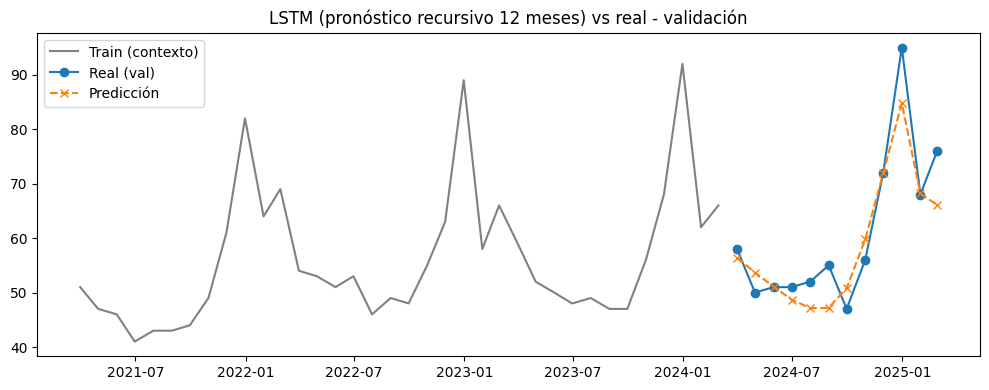

In [18]:
# Ejercicio 5b. LSTM-gráfica:
plot_pred(pred_lstm, "LSTM (pronóstico recursivo 12 meses) vs real - validación")

## F - Conjunto de Prueba y Conclusiones Finales
### Ejercicio 6

ARIMA                3.369
Naive estacional     3.417
Prophet              3.521
LSTM                 4.025
Naive               12.917
dtype: float64

Mejor modelo en validación: ARIMA


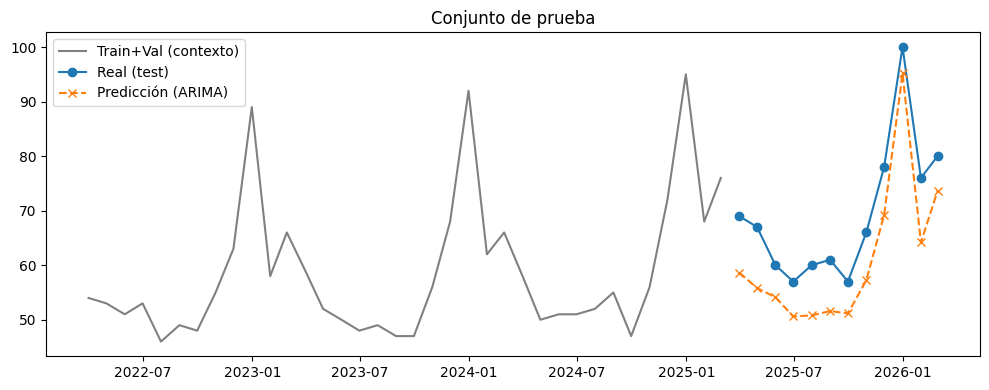

In [19]:
# Ejercicio 6 - mejor modelo (se elige por MAE de validación; se reajusta con train+val)
maes = {"Naive": maeNaive, "Naive estacional": maeSNaive, "ARIMA": maeARIMA,
        "Prophet": maeProphet, "LSTM": maeLSTM}
print(pd.Series(maes).sort_values().round(3))
mejor = min(maes, key=maes.get)
print("\nMejor modelo en validación:", mejor)

tv_R, tv_P = dfr[:-12], dfp[:-12]
ht = len(testR)

if mejor == "Naive":
    pred_test = np.repeat(tv_R["y"].iloc[-1], ht)
elif mejor == "Naive estacional":
    pred_test = tv_R["y"].iloc[-12:].values
elif mejor == "ARIMA":
    pred_test = fc_arima(tv_R["y"], ht, best_order, best_seas)
elif mejor == "Prophet":
    pred_test = fc_prophet(tv_P, testP["ds"], **best_prophet_kw)
else:  # LSTM: nuevo escalador con train+val, mismo nº de épocas que halló early stopping
    scT = MinMaxScaler().fit(tv_R[["y"]])
    s = scT.transform(tv_R[["y"]]).ravel()
    XT, YT = make_seq(s, SEQ)
    mT = build_lstm(32)
    mT.fit(XT, YT, epochs=epochs_usadas, batch_size=16, verbose=0)
    pred_test = scT.inverse_transform(recursive_forecast(mT, s, ht).reshape(-1,1)).ravel()

maeMejor = mae(testR["y"], pred_test)

plt.figure(figsize=(10,4))
plt.plot(tv_R.index[-36:], tv_R["y"][-36:], color="gray", label="Train+Val (contexto)")
plt.plot(testR.index, testR["y"], marker="o", label="Real (test)")
plt.plot(testR.index, pred_test, marker="x", linestyle="--", label=f"Predicción ({mejor})")
plt.title("Conjunto de prueba"); plt.legend(); plt.tight_layout(); plt.show()

In [20]:
print('\nError-del-mejor-modelo-Test : MAE: %.3f' % maeMejor)


Error-del-mejor-modelo-Test : MAE: 8.239


### Ejercicio 7
Comentarios y conclusiones finales

- **Comparación:** En validación, el modelo ingenuo obtuvo un MAE de 12.917, mientras que ARIMA (SARIMA) logró 3.369, el ingenuo estacional 3.417, Prophet 3.521 y LSTM 4.025. Frente al ingenuo, esto representa una reducción del error de aproximadamente 74 % para ARIMA, 73.5 % para el ingenuo estacional, 72.7 % para Prophet y 68.8 % para LSTM. Los cuatro modelos mejoran de forma muy clara al baseline, pero entre ellos las diferencias son pequeñas: ARIMA supera al ingenuo estacional por apenas 0.05 puntos de MAE.
- **Estacionalidad:** La serie de “chocolate” tiene un patrón anual muy marcado, con picos en diciembre y febrero y valles en verano, y esto explica casi todo el resultado. Los modelos que capturan la estacionalidad (SARIMA con s=12, Prophet con estacionalidad anual, el ingenuo estacional y, de forma aprendida, el LSTM) superaron ampliamente al ingenuo simple. Esto se ve en las gráficas: el ingenuo simple es una línea plana, mientras que los demás siguen la forma del año, incluido el pico de diciembre de 2024. Un ARIMA no estacional (ARIMA(1,1,1)) apenas alcanzó 12.07, casi lo mismo que el ingenuo, lo que confirma que la parte estacional es la que aporta el valor.
- **Tendencia/cambios de nivel:** La serie muestra una tendencia creciente: el promedio anual pasó de alrededor de 40 puntos en los primeros años a cerca de 61 en el año de validación y 69 en el de prueba. Los picos también son cada vez más altos, y se nota un salto alrededor de 2020–2021. Esta tendencia es la principal dificultad para los modelos, porque los que se apoyan en la estacionalidad histórica tienden a quedarse en niveles pasados.
- **Complejidad vs. desempeño:** El modelo más complejo, el LSTM, quedó por debajo de ARIMA, Prophet y del ingenuo estacional (MAE de 4.025). Con solo unos 228 puntos mensuales hay poca información para entrenar una red neuronal, y además su error depende de la inicialización y del entrenamiento. En este problema pequeño y muy estacional, los modelos clásicos son más simples, más rápidos, más interpretables y más precisos. El LSTM sí aprendió el patrón anual, pero no justifica su costo adicional aquí. Prophet quedó cerca de ARIMA y requirió poca configuración: su mejor modelo fue multiplicativo con un changepoint_prior_scale bajo (0.01).
- **Prueba final:** Se eligió ARIMA(1,0,0)(1,0,1,12) por su menor MAE de validación, se reajustó con entrenamiento y validación juntos y se evaluó en el último año, con un MAE de 8.239. Es mucho más alto que el de validación (3.369), es decir, unas 2.4 veces mayor. En la gráfica se ve que el modelo capta bien la forma del año y el pico de diciembre de 2025, pero subestima de forma sistemática el nivel entre abril y octubre de 2025, con valores reales más altos. La causa es que el nivel general de interés siguió subiendo y el modelo, sin componente de tendencia (d=0), regresa hacia niveles históricos más bajos. Aun así, 8.239 sigue siendo mejor que el ingenuo simple en prueba (11.75), aunque el ingenuo estacional tuvo un MAE de 8.33 en prueba, prácticamente igual. Es decir, en prueba la ventaja de ARIMA casi desaparece frente a un baseline muy sencillo.
- **Limitaciones:** (1) Solo se usó un año de validación y uno de prueba, por lo que las diferencias pequeñas entre ARIMA, ingenuo estacional y Prophet no son concluyentes. (2) Los datos de Google Trends son un índice relativo de 0 a 100, que depende de la consulta y del periodo descargado. (3) Para el siguiente paso convendría incluir tendencia explícita (por ejemplo, d=1 con diferenciación estacional o un Prophet con más flexibilidad), usar validación con ventanas móviles (walk-forward) y promediar varias corridas del LSTM con distintas semillas.


**++ Fin de la Actividad de la Semana - Pronósticos y Series de Tiempo ++**